<h1><center> Decision Tree Classifier with make_classification

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

In [12]:
# Generate the dataset

X,y = make_classification(
    n_samples=1000,  # Nombre total d'échantillions 1000 points
    n_features= 2,   # Nombre de features 
    n_redundant= 0,   # pas de feature inutile crée artificiellment 
    n_informative= 2,  # Nombre de features utiles pour séparer les classes
    n_classes=2, # Nombre de classe
    n_clusters_per_class=1,  # Chaque classe forme un seul groupe
    random_state= 42)

print(X)

[[ 0.60103418  1.5353525 ]
 [ 0.75594526 -1.1723519 ]
 [ 1.35447877 -0.94852841]
 ...
 [ 2.84431506  0.21129354]
 [-0.02587554  1.6192578 ]
 [ 3.64147835  0.75692519]]


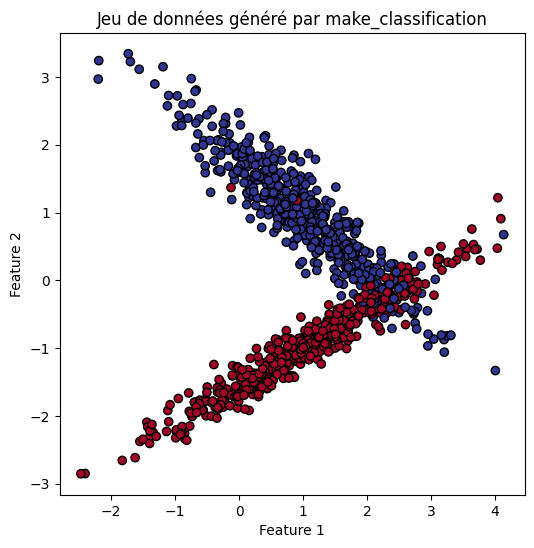

In [15]:
plt.figure(figsize=(6,6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdYlBu, edgecolors='k')
plt.title("Jeu de données généré par make_classification")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [17]:
# Split the data into train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)
print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

800 800
200 200


In [30]:
# intialise and train the model

model = DecisionTreeClassifier(criterion= 'gini', max_depth= 3, random_state= 42)
model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [31]:
# Prédiction
y_pred = model.predict(X_test)

In [32]:
# Evaluation
print("Accuracy :", accuracy_score(y_test, y_pred))
print("classification report : ", classification_report(y_test, y_pred))

Accuracy : 0.92
classification report :                precision    recall  f1-score   support

           0       0.92      0.92      0.92       104
           1       0.92      0.92      0.92        96

    accuracy                           0.92       200
   macro avg       0.92      0.92      0.92       200
weighted avg       0.92      0.92      0.92       200



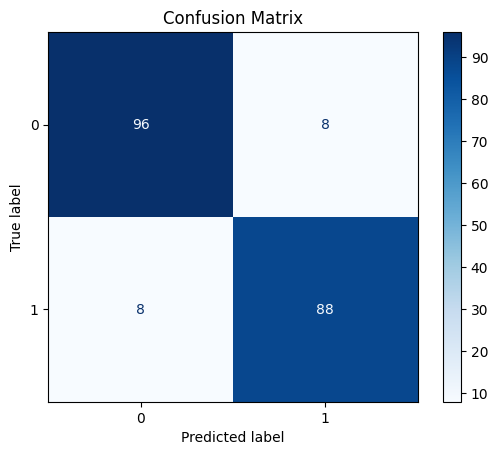

In [33]:
confMat = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confMat)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

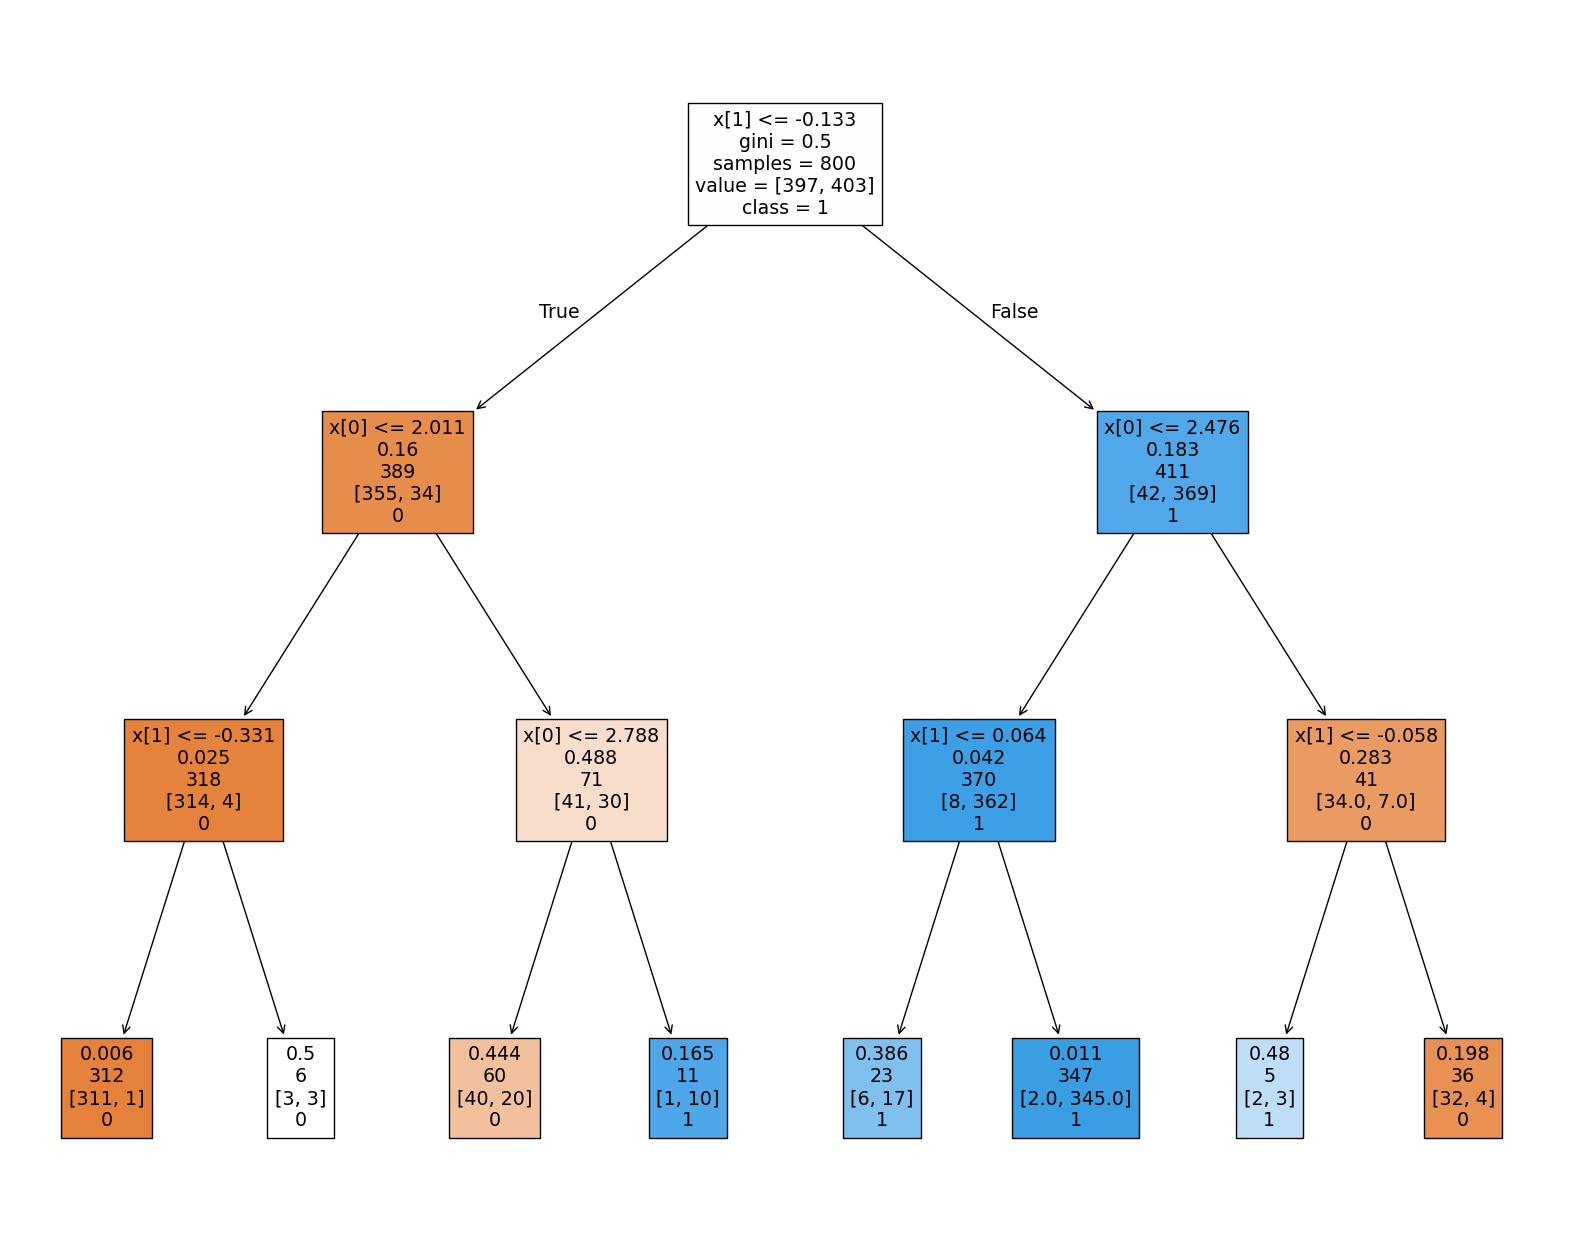

In [34]:
# Tree visualization
plt.figure(figsize=(20,16))
plot_tree(model, filled= True, class_names= ['0', '1'],label='root')
plt.show()

<h1><CENTER>FIN